In [1]:
import dask
from dask.distributed import Client
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.patches as patches
import numpy as np
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmcrameri as cm
import os
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import matplotlib.patches as patches
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import warnings
from cmcrameri import cm
import cfgrib
import glob
import metpy.calc as mpcalc

import babet as bb
import atmicp

warnings.filterwarnings("ignore", category=FutureWarning)
dask.config.set(**{'array.slicing.split_large_chunks': True})

In [2]:
atmicp.style.set_style()

# climate scenario colours from the shared style
CLIM = {'pi': atmicp.style.climate_color('1870'),        # blue
        'curr': atmicp.style.climate_color('present'),   # grey
        'incr': atmicp.style.climate_color('future1')}   # orange

LABEL = {'pi': 'pre-industrial', 'curr': 'current', 'incr': 'increased'}

# one linestyle per perturbation, so climate stays the only thing colour encodes
LS = {'iterated': '-.',
      'iterated_short': ':',
      'tq': '--',
      'ocean': '-',
      'none': '-'}

PERT_LABEL = {'iterated': 'iterated',
              'iterated_short': 'iterated, short',
              'tq': 'ERA5 delta',
              'ocean': 'ocean only',
              'none': 'unperturbed'}

In [3]:
SCALE = {'t': 1.0, 'q': 1e6}  # q in mg/kg, avoids 1e-6 axis offsets
SYMBOL = {'t': 'T', 'q': 'q'}
UNITS = {'t': 'K', 'q': r'mg kg$^{-1}$'}

# deltas are always warmer minus cooler
WARMTH = {'pi': 0, 'curr': 1, 'incr': 2}

# Ignore poles, definition of tropics
LAT_LIMIT = 60
TROPICS_LIMIT = 23.5

# Land sea mask
lsm = atmicp.Data.get_lsm(res='GLO100')

BANDS = {
    'extratropics': lambda lat: (np.abs(lat) > TROPICS_LIMIT) & (np.abs(lat) <= LAT_LIMIT),
    'tropics': lambda lat: np.abs(lat) <= TROPICS_LIMIT,
    'global': lambda lat: np.abs(lat) <= LAT_LIMIT,
}
SURFACES = ['land', 'ocean', 'all']

In [4]:
def land_ocean_stats(da):
    """cos(lat)-weighted mean, std and mean |delta| over land, ocean and global, within LAT_LIMIT."""
    da = da.isel(latitude=np.abs(da.latitude.values) <= LAT_LIMIT)
    mask = lsm.sel(latitude=da.latitude, longitude=da.longitude)

    masks = {'land': mask > 0.5, 'ocean': mask <= 0.5,
             'global': xr.ones_like(mask, dtype=bool)}
    coslat = np.cos(np.deg2rad(da.latitude))
    dims = ('latitude', 'longitude')

    stats = []
    for m in masks.values():
        w = (coslat * m).astype(float)
        stats.append(xr.concat([da.weighted(w).mean(dims),
                                da.weighted(w).std(dims),
                                np.abs(da).weighted(w).mean(dims)],
                               dim=pd.Index(['mean', 'std', 'absmean'], name='stat')))

    return xr.concat(stats, dim=pd.Index(list(masks), name='region'))


def band_surface_mean(da):
    """cos(lat)-weighted mean per latitude band (BANDS) and surface (SURFACES), members kept."""
    da = da.isel(latitude=np.abs(da.latitude.values) <= LAT_LIMIT)
    lat = da.latitude
    mask = lsm.sel(latitude=lat, longitude=da.longitude)

    masks = {'land': mask > 0.5, 'ocean': mask <= 0.5,
             'all': xr.ones_like(mask, dtype=bool)}
    coslat = np.cos(np.deg2rad(lat))

    # one dask graph for every band and surface, so the fields are read once
    return xr.concat(
        [xr.concat([da.weighted((coslat * in_band(lat) * masks[surface]).astype(float))
                      .mean(('latitude', 'longitude'))
                    for surface in SURFACES],
                   dim=pd.Index(SURFACES, name='surface'))
         for in_band in BANDS.values()],
        dim=pd.Index(list(BANDS), name='band'))

In [11]:
def tendency_bars(amp):
    """Bars of the regional-mean |member-wise delta| in surface pressure tendency, one panel per initialisation.

    Bar: member mean; whisker: ±1 member standard deviation.
    """
    areas = list(amp.area.values)
    series = [(climate, pert) for climate in amp.climate.values for pert in amp.perturbation.values]
    fig, axes = plt.subplots(1, amp.inidate.size, sharex=True, sharey=True,
                             figsize=(atmicp.style.REF_WIDTH, 0.45 * atmicp.style.REF_WIDTH))

    fs_title = atmicp.style.scaled(atmicp.style.FS_TITLE, fig)
    fs_label = atmicp.style.scaled(atmicp.style.FS_LABEL, fig)
    fs_tick = atmicp.style.scaled(atmicp.style.FS_TICK, fig)
    fs_annot = atmicp.style.scaled(atmicp.style.FS_ANNOT, fig)

    # land/ocean pairs grouped, latitude bands spaced apart
    x = np.arange(len(areas)) + 0.3 * (np.arange(len(areas)) // len(TENDENCY_SURFACES))
    width = 0.8 / len(series)
    for ax, inidate in zip(axes, amp.inidate.values):
        for j, (climate, pert) in enumerate(series):
            s = amp.sel(inidate=inidate, climate=climate, perturbation=pert)
            ax.bar(x + width * (j - (len(series) - 1) / 2), s.mean('number'), width=width,
                   yerr=s.std('number')/np.sqrt(s.sizes['number']), color=CLIM[climate], alpha=PERT_ALPHA[pert],
                   linewidth=0, error_kw={'ecolor': atmicp.style.INK, 'elinewidth': 1, 'capsize': 0.5})

        ax.set_title(f'initialised {pd.Timestamp(inidate):%Y-%m-%d}', fontsize=fs_label)
        ax.set_xticks(x, [surface for _, surface in areas])
        
        # band names centred under each land/ocean pair
        band_x = x.reshape(-1, len(TENDENCY_SURFACES)).mean(axis=1)
        sec = ax.secondary_xaxis('bottom')
        sec.set_xticks(band_x, [band for band, _ in areas[::len(TENDENCY_SURFACES)]],
                       fontsize=fs_label)
        sec.tick_params(length=0, pad=atmicp.style.scaled(20, fig))
        sec.spines['bottom'].set_visible(False)
        ax.tick_params(axis='both', labelsize=fs_tick, left=True, direction='out',
                       length=atmicp.style.scaled(3.5, fig),
                       width=atmicp.style.scaled(0.8, fig), color=atmicp.style.INK)

    axes[0].set_ylabel(TENDENCY_LABEL, fontsize=fs_label)
    sns.despine(fig=fig)
    atmicp.style.panel_labels(axes)

    fig.suptitle(f'Surface pressure tendency, delta against {LABEL["curr"]}, {PERT_LABEL["none"]}',
                 fontsize=fs_title, fontweight='bold')
    fig.tight_layout(rect=[0, 0.08, 1, 0.98])
    fig.legend(handles=[patches.Patch(color=CLIM[climate], alpha=PERT_ALPHA[pert], linewidth=0,
                                      label=f'{LABEL[climate]}, {PERT_LABEL[pert]}')
                        for climate, pert in series],
               loc='lower center', ncol=len(series), frameon=False, fontsize=fs_annot)

    return fig

# Calculate pressure tendencies

now done in ```scripts/calc_pressure_tendency.py```

In [7]:
dlnpsdt = xr.open_dataset('/gf5/predict/AWH019_ERMIS_ATMICP/DATA/postproc/pressure_tendency/ifs_pressure_tendency_GLO100.nc').dlnpsdt

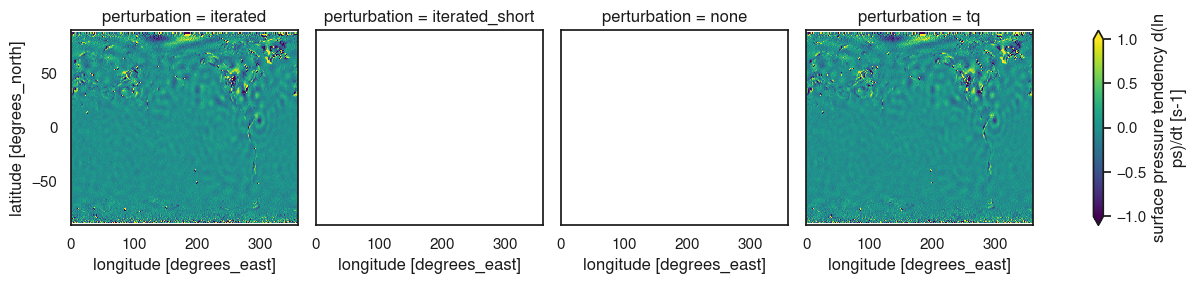

In [6]:
inidate = '2021-06-22'
diff = dlnpsdt.sel(climate='incr') - dlnpsdt.sel(climate='curr', perturbation='none')
(diff.sel(number=2, inidate=inidate, time=inidate)*10000000).plot(vmin=-1, vmax=1, col='perturbation')


In [6]:
diff = xr.concat([dlnpsdt.sel(climate=c)-dlnpsdt.sel(climate='curr', perturbation='none') for c in ['pi', 'incr']], dim=pd.Index(['pi', 'incr'], name='climate'))
# bands = band_surface_mean(dlnpsdt.sel(c))

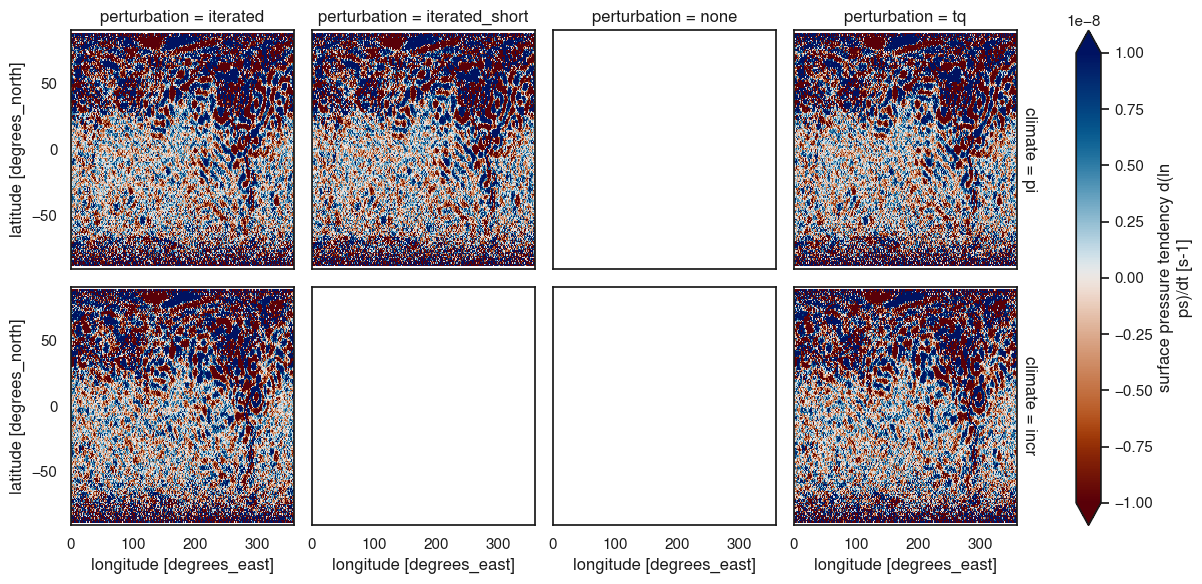

In [15]:
vmax = 1e-8
inidate = '2021-06-22'
diff = diff.dropna(dim='number', how='all')
diff.sel(number=2, inidate=inidate, time=inidate).plot(vmin=-vmax, vmax=vmax, col='perturbation', row='climate', cmap=cm.vik_r)

# Surface pressure tendency at initialisation

Member-wise difference per grid box, then the regional mean of its amplitude.

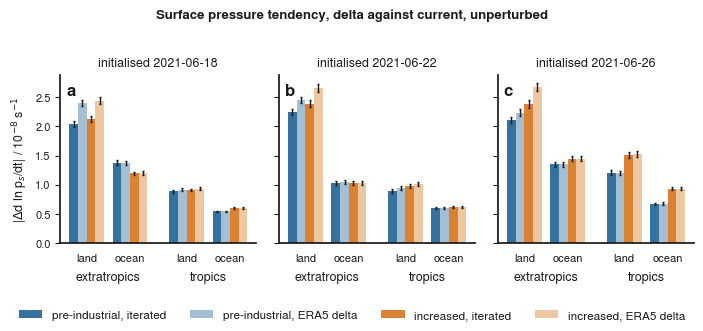

In [12]:
TENDENCY_BANDS = ['extratropics', 'tropics']
TENDENCY_SURFACES = ['land', 'ocean']
PERT_ALPHA = {'iterated': 1.0, 'tq': 0.45}
TENDENCY_SCALE = 1e8
TENDENCY_LABEL = r'|$\Delta$d ln p$_s$/dt| / 10$^{-8}$ s$^{-1}$'

# initial time of each initialisation
initial = dlnpsdt.sel(time=dlnpsdt.inidate).drop_vars('time')

# member-wise difference per grid box, then the regional mean of its amplitude
tendency_diff = (initial.sel(climate=['pi', 'incr'], perturbation=['iterated', 'tq'])
                 - initial.sel(climate='curr', perturbation='none', drop=True))
tendency_amp = (TENDENCY_SCALE * band_surface_mean(np.abs(tendency_diff))
                .sel(band=TENDENCY_BANDS, surface=TENDENCY_SURFACES)
                .stack(area=('band', 'surface'))).compute()

fig = tendency_bars(tendency_amp)
atmicp.style.save(fig, '13_tendency_bars_mean-sem', dpi=600)
plt.show()